# Practical 2: Foundations of Statistics

**Dataset:** TeachingRatings.csv (teaching evaluations of university instructors)

**Aim:** Understand the dataset type, compute descriptive statistics, plot a histogram and compare groups.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ratings = pd.read_csv("TeachingRatings.csv")
ratings.head(10)

   rownames minority  age  gender  ... tenure  students  allstudents prof
0         1      yes   36  female  ...    yes        24           43    1
1         2       no   59    male  ...    yes        17           20    2
2         3       no   51    male  ...    yes        55           55    3
3         4       no   40  female  ...    yes        40           46    4
4         5       no   31  female  ...    yes        42           48    5
5         6       no   62    male  ...    yes       182          282    6
6         7       no   33  female  ...    yes        33           41    7
7         8       no   51  female  ...    yes        25           41    8
8         9       no   33  female  ...    yes        48           60    9
9        10       no   47    male  ...     no        16           19   10

[10 rows x 13 columns]

In [2]:
print(ratings.shape)
ratings.info()

(463, 13)
<class 'pandas.DataFrame'>
RangeIndex: 463 entries, 0 to 462
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   rownames     463 non-null    int64  
 1   minority     463 non-null    str    
 2   age          463 non-null    int64  
 3   gender       463 non-null    str    
 4   credits      463 non-null    str    
 5   beauty       463 non-null    float64
 6   eval         463 non-null    float64
 7   division     463 non-null    str    
 8   native       463 non-null    str    
 9   tenure       463 non-null    str    
 10  students     463 non-null    int64  
 11  allstudents  463 non-null    int64  
 12  prof         463 non-null    int64  
dtypes: float64(2), int64(5), str(6)
memory usage: 47.2 KB


**Result:** The data has 463 rows and 13 columns with no missing values.

**Dataset type:** Cross-sectional. Each row is a course taught by one of 94 instructors, recorded at one point in time. The same instructors are not followed over several time periods, so it is not a time series.

In [3]:
s = ratings["students"]
summary = pd.Series({"Mean": s.mean(), "Median": s.median(), "Minimum": s.min(), "Maximum": s.max()})
print(summary.round(2))

Mean        36.62
Median      23.00
Minimum      5.00
Maximum    380.00
dtype: float64


**Result:** On average 36.62 students answered per course. The median is 23, which is lower than the mean, so a few very large classes (maximum 380) pull the mean up.

In [4]:
ratings.describe().round(3)

       rownames      age   beauty     eval  students  allstudents     prof
count   463.000  463.000  463.000  463.000   463.000      463.000  463.000
mean    232.000   48.365    0.000    3.998    36.624       55.177   45.434
std     133.801    9.803    0.789    0.555    45.018       75.073   27.509
min       1.000   29.000   -1.450    2.100     5.000        8.000    1.000
25%     116.500   42.000   -0.656    3.600    15.000       19.000   20.000
50%     232.000   48.000   -0.068    4.000    23.000       29.000   44.000
75%     347.500   57.000    0.546    4.400    40.000       60.000   70.500
max     463.000   73.000    1.970    5.000   380.000      581.000   94.000

**Result:** The table gives count, mean, standard deviation, minimum, quartiles and maximum for every numeric column. Average age is about 48 years and average evaluation score is about 4.0.

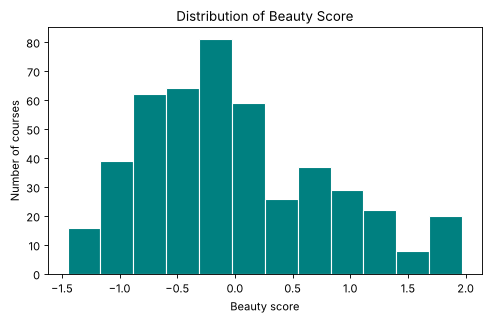

In [5]:
plt.figure(figsize=(7, 4))
plt.hist(ratings["beauty"], bins=12, color="teal", edgecolor="white")
plt.title("Distribution of Beauty Score")
plt.xlabel("Beauty score")
plt.ylabel("Number of courses")
plt.show()

In [6]:
b = ratings["beauty"]
shape_stats = pd.Series({"Mean": b.mean(), "Median": b.median(), "Std dev": b.std(), "Skewness": b.skew(), "Kurtosis": b.kurt()})
print(shape_stats.round(4))
tilt = "right (positive)" if shape_stats["Skewness"] > 0 else "left (negative)"

Mean        0.0000
Median     -0.0680
Std dev     0.7886
Skewness    0.5158
Kurtosis   -0.3848
dtype: float64


**Result:** The histogram is centred close to zero. Skewness is 0.516, so the distribution is slightly skewed to the right (positive). Kurtosis is negative, so the curve is a little flatter than a normal curve.

In [7]:
by_gender = ratings.groupby("gender")["beauty"].agg(["mean", "std", "count"]).round(4)
by_gender

          mean     std  count
gender                       
female  0.1161  0.8178    195
male   -0.0845  0.7571    268

In [8]:
f_mean = by_gender.loc["female", "mean"]
m_mean = by_gender.loc["male", "mean"]
f_std = by_gender.loc["female", "std"]
m_std = by_gender.loc["male", "std"]
print(f_mean, m_mean, f_std, m_std)

0.1161 -0.0845 0.8178 0.7571


**Result:** Yes, the average beauty score differs by gender. Female instructors average 0.1161 (std 0.8178) and male instructors average -0.0845 (std 0.7571). Females score slightly higher and are slightly more spread out.

In [9]:
counts = pd.crosstab(ratings["gender"], ratings["tenure"])
percent = counts.div(counts.sum(axis=1), axis=0).mul(100).round(2)
print(counts)
print()
print(percent)
f_ten = percent.loc["female", "yes"]
m_ten = percent.loc["male", "yes"]

tenure  no  yes
gender         
female  50  145
male    52  216

tenure     no    yes
gender              
female  25.64  74.36
male    19.40  80.60


**Result:** 80.6% of male instructors and 74.36% of female instructors have tenure. Tenure status differs slightly by gender, with a higher share of men holding tenure.